In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.io import loadmat
import tifffile as tiff
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from matplotlib.colors import ListedColormap, BoundaryNorm
import seaborn as sns

#doing all again with the reshaped data: note Beech forest disappears from the shriking of the data

# Load Classification Data
classification_tree_file = "/home/laura93schade/data/tree_species/tree_species_index_info.txt"
tree_classification_tif = '/home/laura93schade/data/tree_species/vm_btpolygonproved_target_clip_mask_chm_rev_flipped.tif'
classification_tree_array = tiff.imread(tree_classification_tif)

# Load classification data
df_tree_species = pd.read_csv(classification_tree_file)

# Remove extra spaces from column names
df_tree_species.columns = df_tree_species.columns.str.strip()

# Print cleaned column names
print("Cleaned column names:", df_tree_species.columns)

# Define the new row with correct column names
new_row = pd.DataFrame([[0, "1", "1", 0]], columns=['Index', 'Code', 'Name', 'Count'])

# Concatenate with the original DataFrame
df_tree_species = pd.concat([new_row, df_tree_species], axis=0, ignore_index=True)

# Print DataFrame to verify changes
print("DataFrame after concatenation:")
print(df_tree_species.head())
print("Columns after concatenation:", df_tree_species.columns)

tree_classification_tif = tiff.imread(tree_classification_tif)
classification_tree_array = np.array(tree_classification_tif)

# Print the shape and first few values of the classification data
print(f"Shape of classification_tree_array: {classification_tree_array.shape}")
print("First few values of classification_tree_array:")
print(classification_tree_array[:5, :5])

Cleaned column names: Index(['Index', 'Code', 'Name', 'Count'], dtype='object')
DataFrame after concatenation:
   Index  Code                                Name  Count
0      0     1                                   1      0
1      1   AA0                        Aspen forest  64389
2      2   AA1                         Pine forest   5199
3      3   AA2   Beech forest with deciduous woods   2884
4      4   AB0                  Douglas fir forest  11593
Columns after concatenation: Index(['Index', 'Code', 'Name', 'Count'], dtype='object')
Shape of classification_tree_array: (326, 840)
First few values of classification_tree_array:
[[0 0 0 0 0]
 [0 0 0 0 0]
 [0 0 0 0 0]
 [0 0 0 0 0]
 [0 0 0 0 0]]


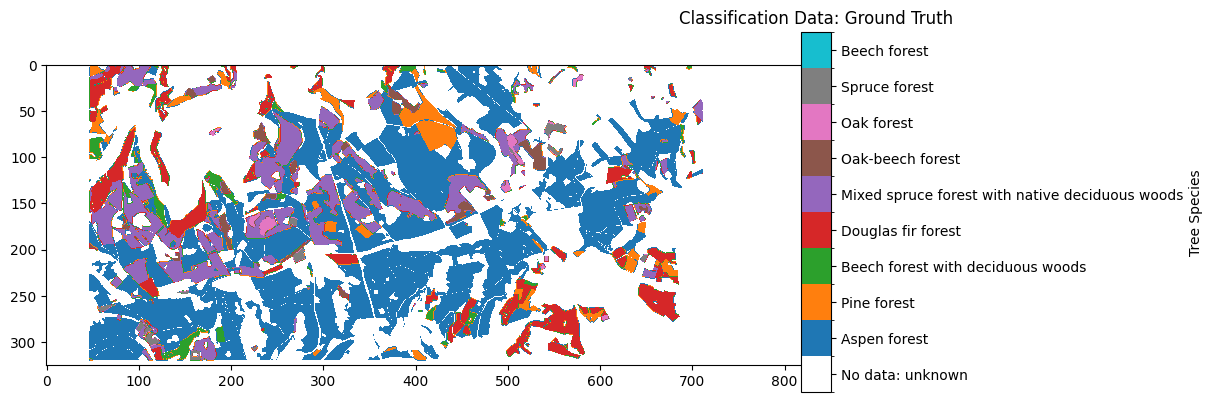

In [3]:
# Plot Classification data
cmap = plt.get_cmap('tab10', 10)
cmap = mcolors.ListedColormap(['white'] + list(cmap.colors))
bounds = np.arange(-0.5, 10.5, 1)
norm = mcolors.BoundaryNorm(bounds, cmap.N)
fig = plt.figure(figsize=(10, 6), dpi=100)
img = plt.imshow(classification_tree_array, cmap=cmap, norm=norm)

# Define custom labels for the colorbar
labels = [
    'No data: unknown',  # Corresponding to 0 value
    'Aspen forest',
    'Pine forest',
    'Beech forest with deciduous woods',
    'Douglas fir forest',
    'Mixed spruce forest with native deciduous woods',
    'Oak-beech forest',
    'Oak forest',
    'Spruce forest',
    'Beech forest'
]

# Create a colorbar with a custom size
cbar_ax = fig.add_axes([0.88, 0.2, 0.03, 0.6])  # [left, bottom, width, height]
cbar = plt.colorbar(img, cax=cbar_ax, label='Tree Species')
cbar.set_ticks(np.arange(0, 10))  # Set ticks to match the number of labels
cbar.set_ticklabels(labels)  # Set tick labels
plt.title('Classification Data: Ground Truth')
plt.show()

Sample Predictions Data:
   Unnamed: 0         x         y  x_square  y_square     z_P_0     z_P_1  \
0    0.000000  0.000000  0.597892       0.0      0.55  0.564894  0.583244   
1    0.000012  0.000000  0.599398       0.0      0.55  0.460990  0.475575   
2    0.000024  0.000000  0.906627       0.0      0.90  0.387253  0.426644   
3    0.000037  0.000000  0.908133       0.0      0.90  0.373154  0.410420   
4    0.000049  0.003125  0.585843       0.0      0.55  0.524713  0.515582   

      z_P_2     z_P_3     z_P_4  ...    z_P_31    z_P_32    z_P_33    z_P_34  \
0  0.597784  0.612135  0.620656  ...  0.382243  0.393133  0.403875  0.590928   
1  0.491774  0.510861  0.526684  ...  0.461950  0.458661  0.469982  0.642546   
2  0.463138  0.492785  0.514075  ...  0.350174  0.340689  0.354470  0.580339   
3  0.442656  0.468237  0.486426  ...  0.356697  0.410094  0.449611  0.630389   
4  0.502236  0.494511  0.487959  ...  0.502481  0.488269  0.454543  0.581124   

     z_P_35  polarimetry  class

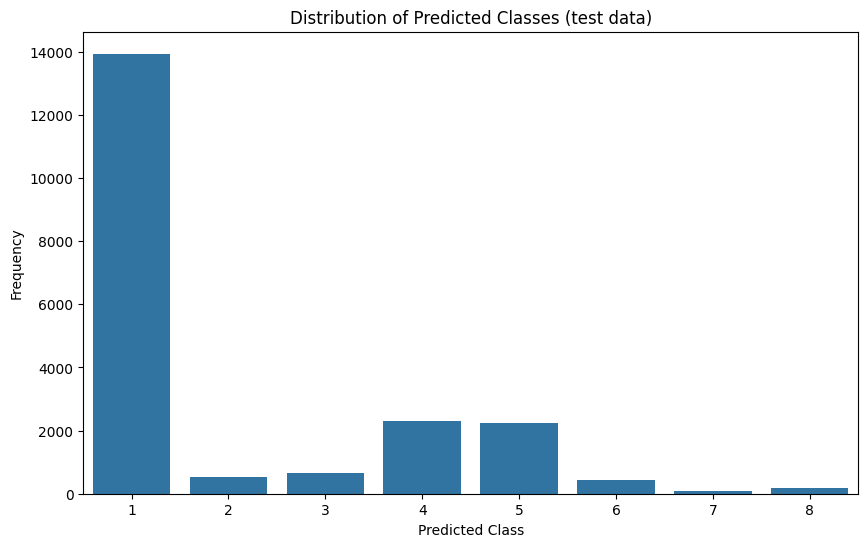

In [4]:
# Load Predictions Data
predictions_test_file = '/home/laura93schade/local/class/dname_geo_split_square__polunion:_no__target_class__timelim_10000.0__modelset_best_quality__tsp_1.0__polarim_0__colset_withx__uuid_fd791bd1-/predictions_test.csv'
predictions_train_file = '/home/laura93schade/local/class/dname_geo_split_square__polunion:_no__target_class__timelim_10000.0__modelset_best_quality__tsp_1.0__polarim_0__colset_withx__uuid_fd791bd1-/predictions_train.csv'
predictions_test_df = pd.read_csv(predictions_test_file)
predictions_train_df = pd.read_csv(predictions_train_file)

print("Sample Predictions Data:")
print(predictions_test_df.head())

plt.figure(figsize=(10, 6))
sns.countplot(data=predictions_test_df, x='predicted')
plt.title('Distribution of Predicted Classes (test data)')
plt.xlabel('Predicted Class')
plt.ylabel('Frequency')
plt.show()

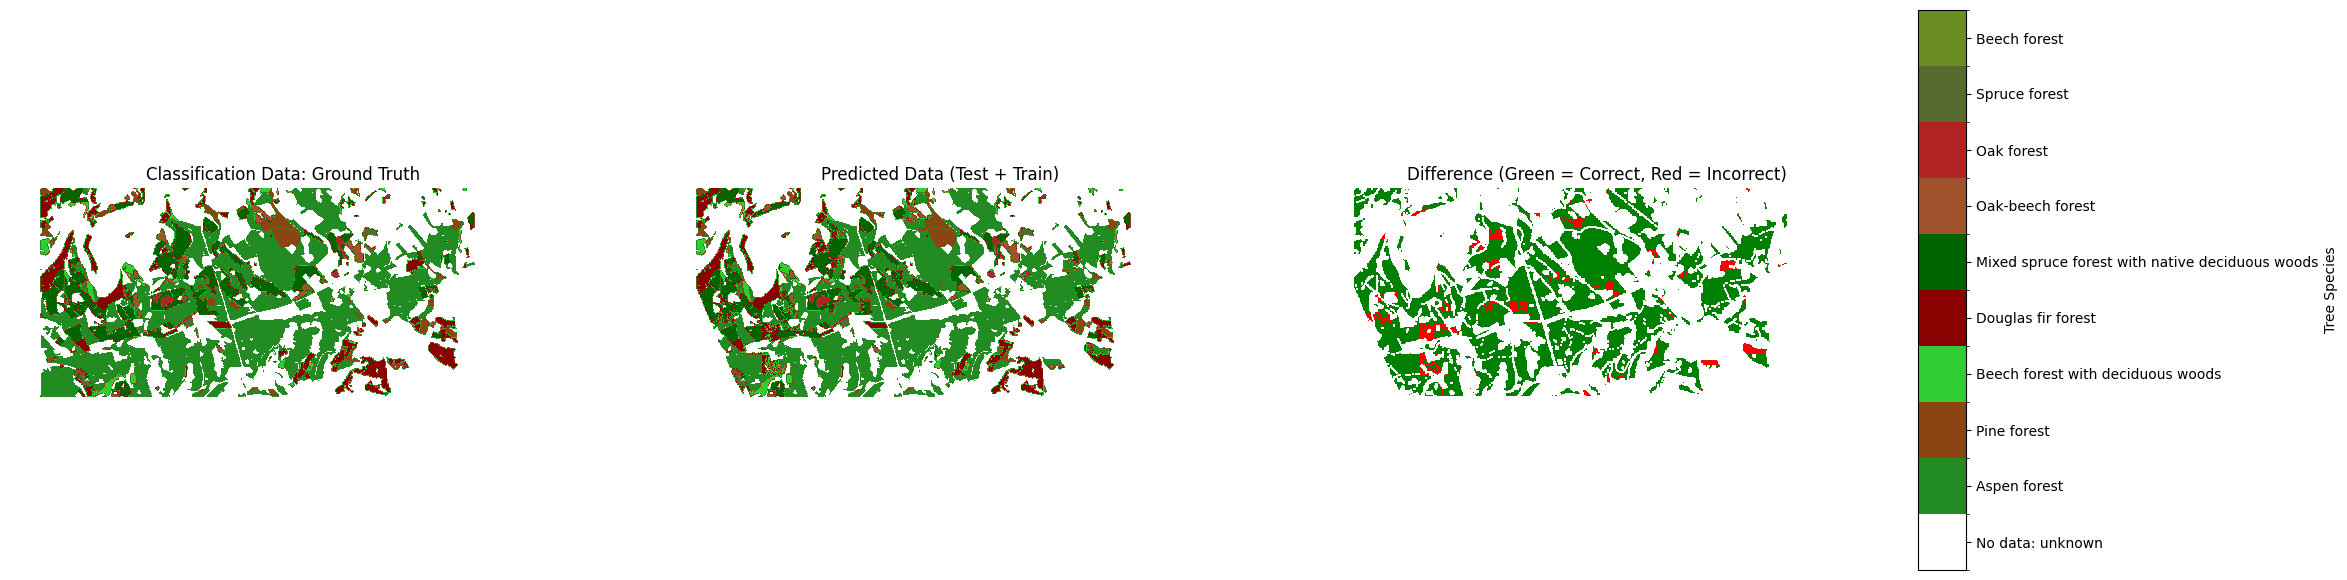

In [5]:
# Create empty arrays for predictions with the same shape as classification data
predicted_test_array = np.zeros_like(classification_tree_array)
predicted_train_array = np.zeros_like(classification_tree_array)

# Populate the predicted test array
for _, row in predictions_test_df.iterrows():
    x, y = int(row['original_x']), int(row['original_y'])
    predicted_class = int(row['predicted'])
    if x < predicted_test_array.shape[0] and y < predicted_test_array.shape[1]:  # Ensure within bounds
        predicted_test_array[x, y] = predicted_class

# Populate the predicted train array
for _, row in predictions_train_df.iterrows():
    x, y = int(row['original_x']), int(row['original_y'])
    predicted_class = int(row['predicted'])
    if x < predicted_train_array.shape[0] and y < predicted_train_array.shape[1]:  # Ensure within bounds
        predicted_train_array[x, y] = predicted_class

# Combine test and train predictions for visualization
combined_predictions_array = np.copy(predicted_test_array)
combined_predictions_array[predicted_train_array != 0] = predicted_train_array[predicted_train_array != 0]
combined_predictions_array=combined_predictions_array

# Convert arrays to a higher capacity integer type
classification_tree_array = classification_tree_array.astype(np.int16)
predicted_test_array = predicted_test_array.astype(np.int16)
predicted_train_array = predicted_train_array.astype(np.int16)
combined_predictions_array = combined_predictions_array.astype(np.int16)

# Compute the difference array using np.nan for missing predictions
difference_array = np.full_like(classification_tree_array, np.nan, dtype=np.float32)
for _, row in predictions_test_df.iterrows():
    x, y = int(row['original_x']), int(row['original_y'])
    if x < difference_array.shape[0] and y < difference_array.shape[1] and classification_tree_array[x, y] != 0:  # Ensure within bounds and not zero in classification
        difference_array[x, y] = classification_tree_array[x, y] - predicted_test_array[x, y]

for _, row in predictions_train_df.iterrows():
    x, y = int(row['original_x']), int(row['original_y'])
    if x < difference_array.shape[0] and y < difference_array.shape[1] and classification_tree_array[x, y] != 0:  # Ensure within bounds and not zero in classification
        difference_array[x, y] = classification_tree_array[x, y] - predicted_train_array[x, y]

# Create an array for correct/incorrect predictions
correctness_array = np.where(np.isnan(difference_array), np.nan, np.where(difference_array == 0, 1, 0))

# Plotting the Classification Data
fig, ax = plt.subplots(1, 3, figsize=(24, 8), dpi=100)

# Define custom colormap and normalization for tree species
tree_colors = ['#FFFFFF', '#228B22', '#8B4513', '#32CD32', '#8B0000', '#006400', '#A0522D', '#B22222', '#556B2F', '#6B8E23']
cmap = ListedColormap(tree_colors)
bounds = np.arange(-0.5, 10.5, 1)
norm = BoundaryNorm(bounds, cmap.N)

# Classification Data Plot
ax[0].imshow(classification_tree_array, cmap=cmap, norm=norm)
ax[0].set_title('Classification Data: Ground Truth')
ax[0].axis('off')

# Predictions Data Plot (combined test and train)
ax[1].imshow(combined_predictions_array, cmap=cmap, norm=norm)
ax[1].set_title('Predicted Data (Test + Train)')
ax[1].axis('off')

# Define colormap for correctness
correctness_cmap = ListedColormap(['red', 'green'])
correctness_norm = BoundaryNorm([0, 0.5, 1], correctness_cmap.N)

# Correctness Data Plot
ax[2].imshow(correctness_array, cmap=correctness_cmap, norm=correctness_norm)
ax[2].set_title('Difference (Green = Correct, Red = Incorrect)')
ax[2].axis('off')

# Add colorbars
cbar_ax = fig.add_axes([0.92, 0.15, 0.02, 0.7])
cbar = plt.colorbar(ax[0].images[0], cax=cbar_ax, orientation='vertical')
cbar.set_ticks(np.arange(0, 10))
cbar.set_ticklabels([
    'No data: unknown', 'Aspen forest', 'Pine forest', 
    'Beech forest with deciduous woods', 'Douglas fir forest',
    'Mixed spruce forest with native deciduous woods', 'Oak-beech forest', 
    'Oak forest', 'Spruce forest', 'Beech forest'
])
cbar.set_label('Tree Species')

plt.show()


/var/tmp/ipykernel_28504/2090328797.py:30: RuntimeWarning: invalid value encountered in cast
  tiff.imwrite(difference_tif_path, (correctness_array * 255).astype(np.uint8))  # Scale to 255 for visualization


Difference array saved to /home/laura93schade/2024-ESL-BiomassSAR/notebooks/difference_array.tif


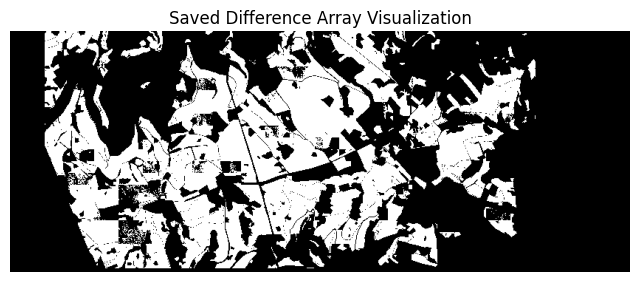

In [6]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, BoundaryNorm
import tifffile as tiff
import os

# Directory to save the TIFF files
notebooks_dir = os.path.expanduser('~/2024-ESL-BiomassSAR/notebooks/')

# Define colormap and normalization for difference
difference_cmap = ListedColormap(['red', 'green'])
difference_norm = BoundaryNorm([0, 0.5, 1], difference_cmap.N)

# Plotting the Difference Data
fig, ax = plt.subplots(figsize=(8, 8), dpi=100)

# Difference Data Plot
cax = ax.imshow(correctness_array, cmap=difference_cmap, norm=difference_norm)
ax.set_title('Difference (Green = Correct, Red = Incorrect)')
ax.axis('off')

# Add colorbar
cbar = plt.colorbar(cax, ax=ax, orientation='vertical')
cbar.set_ticks([0, 1])
cbar.set_ticklabels(['Incorrect', 'Correct'])
cbar.set_label('Correctness')

# Save the difference array as TIFF
difference_tif_path = os.path.join(notebooks_dir, 'difference_array.tif')
tiff.imwrite(difference_tif_path, (correctness_array * 255).astype(np.uint8))  # Scale to 255 for visualization
plt.savefig(os.path.join(notebooks_dir, 'difference_plot.png'), format='png', bbox_inches='tight', pad_inches=0.1, dpi=100)
plt.close()

print(f"Difference array saved to {difference_tif_path}")

# Load and display the saved TIFF plot to verify
saved_difference = tiff.imread(difference_tif_path)
plt.figure(figsize=(8, 8))
plt.imshow(saved_difference, cmap='gray')
plt.title('Saved Difference Array Visualization')
plt.axis('off')
plt.show()


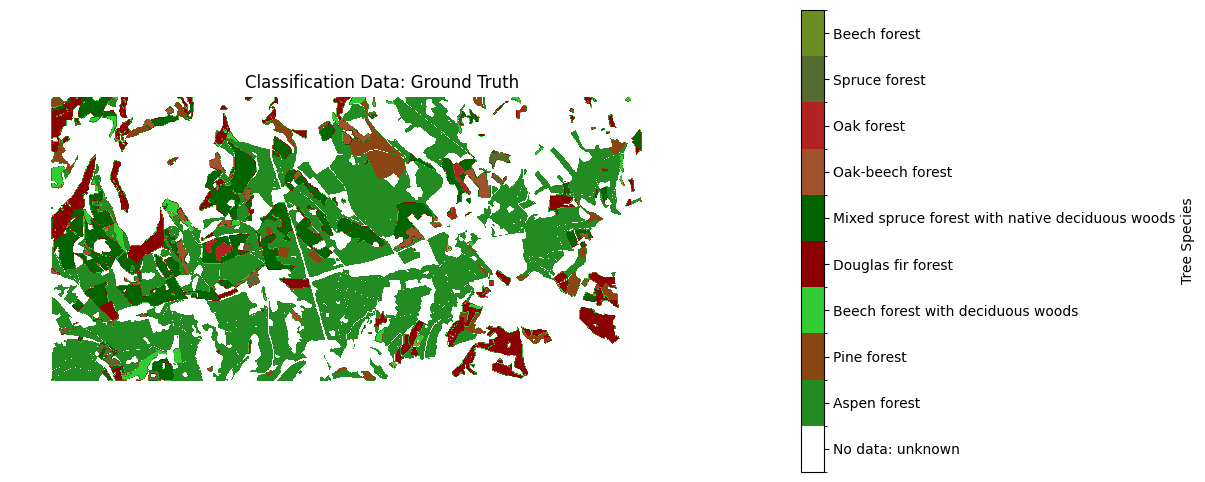

In [7]:
#plotting Ground Truth alone
# Define custom colormap and normalization for tree species
tree_colors = ['#FFFFFF', '#228B22', '#8B4513', '#32CD32', '#8B0000', '#006400', '#A0522D', '#B22222', '#556B2F', '#6B8E23']
cmap = ListedColormap(tree_colors)
bounds = np.arange(-0.5, 10.5, 1)
norm = BoundaryNorm(bounds, cmap.N)

# Plot and show the Classification Data
plt.figure(figsize=(12, 12), dpi=100)  # Larger figure size
plt.imshow(classification_tree_array, cmap=cmap, norm=norm)
plt.title('Classification Data: Ground Truth')
plt.axis('off')

# Adjust the color bar size
cbar = plt.colorbar(ticks=np.arange(0, 10), shrink=0.5)  # Smaller color bar
cbar.set_ticklabels([
    'No data: unknown', 'Aspen forest', 'Pine forest', 
    'Beech forest with deciduous woods', 'Douglas fir forest',
    'Mixed spruce forest with native deciduous woods', 'Oak-beech forest', 
    'Oak forest', 'Spruce forest', 'Beech forest'
])
cbar.set_label('Tree Species')
plt.show()


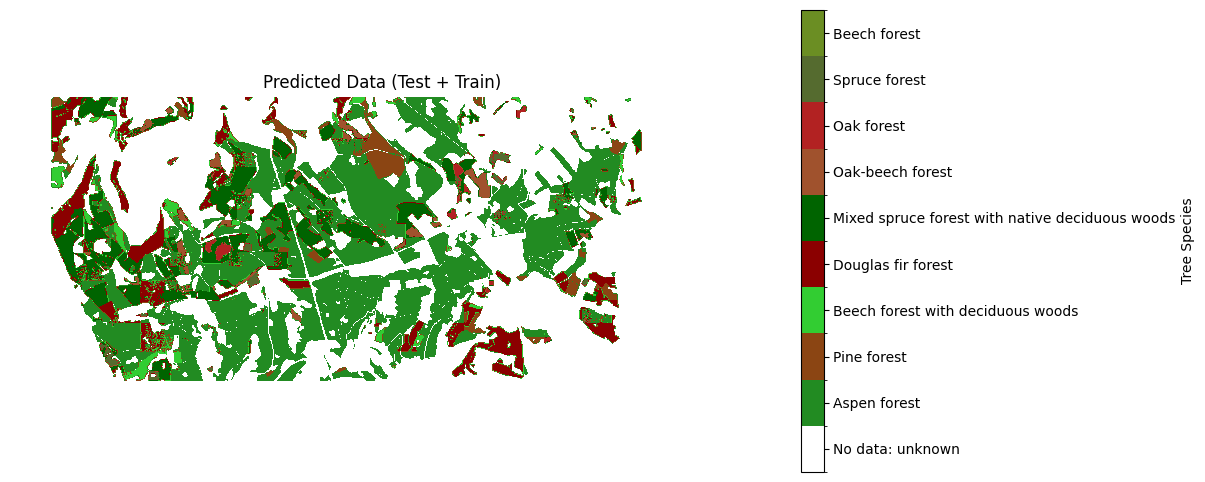

In [8]:
#plot 2: predicted data
# Plot and show the Predicted Data
plt.figure(figsize=(12, 12), dpi=100)  # Larger figure size
plt.imshow(combined_predictions_array, cmap=cmap, norm=norm)
plt.title('Predicted Data (Test + Train)')
plt.axis('off')

# Adjust the color bar size
cbar = plt.colorbar(ticks=np.arange(0, 10), shrink=0.5)  # Smaller color bar
cbar.set_ticklabels([
    'No data: unknown', 'Aspen forest', 'Pine forest', 
    'Beech forest with deciduous woods', 'Douglas fir forest',
    'Mixed spruce forest with native deciduous woods', 'Oak-beech forest', 
    'Oak forest', 'Spruce forest', 'Beech forest'
])
cbar.set_label('Tree Species')
plt.show()

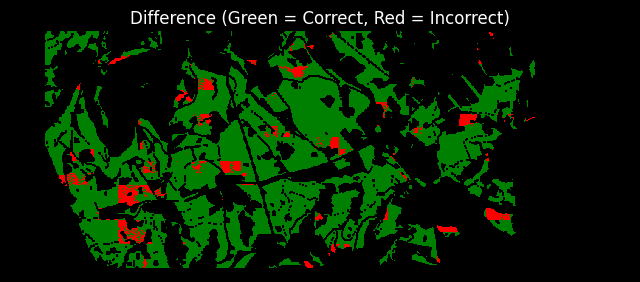

In [10]:
#plot 3: difference

# Define colormap for correctness
correctness_cmap = ListedColormap(['red', 'green'])
correctness_norm = BoundaryNorm([0, 0.5, 1], correctness_cmap.N)

# Set the style for the plot
plt.style.use('dark_background')

# Plot and show the Correctness Data
plt.figure(figsize=(8, 8), dpi=100)
plt.imshow(correctness_array, cmap=correctness_cmap, norm=correctness_norm)
plt.title('Difference (Green = Correct, Red = Incorrect)')
plt.axis('off')
plt.show()

Plotting test and train predictions separately

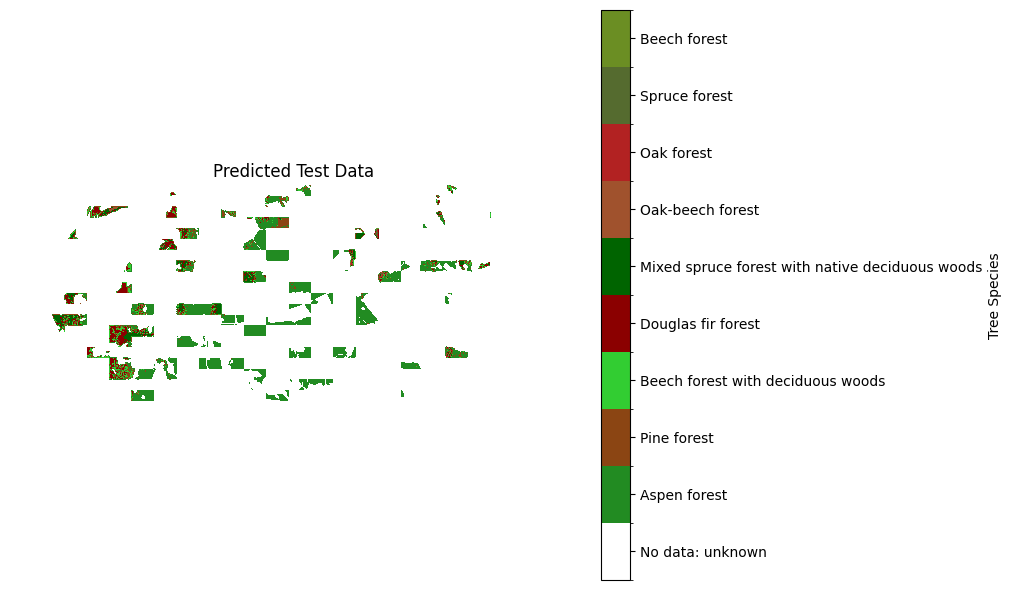

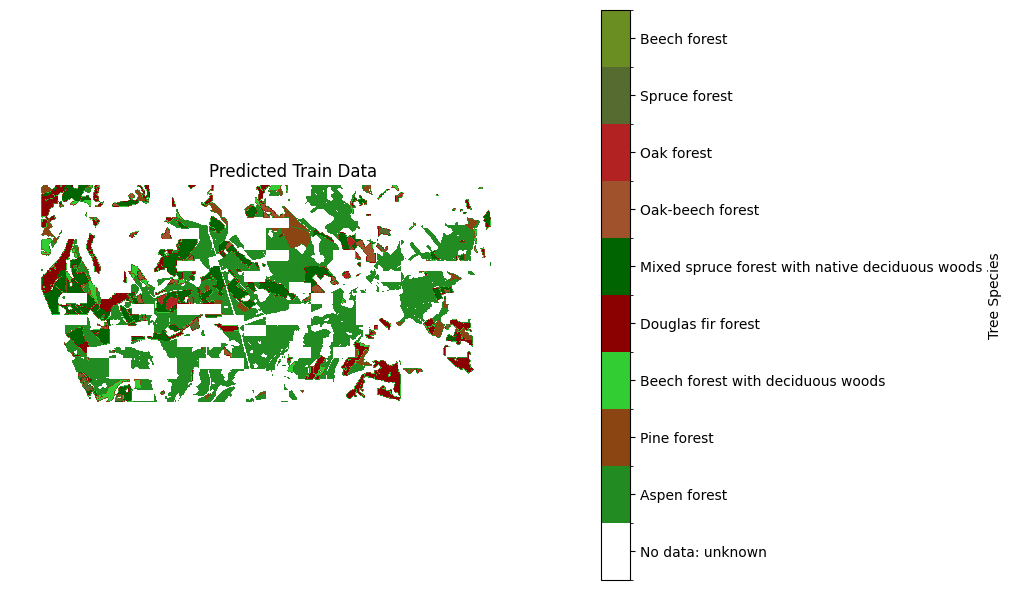

In [24]:
# Define custom colormap and normalization for tree species
tree_colors = ['#FFFFFF', '#228B22', '#8B4513', '#32CD32', '#8B0000', '#006400', '#A0522D', '#B22222', '#556B2F', '#6B8E23']
cmap = ListedColormap(tree_colors)
bounds = np.arange(-0.5, 10.5, 1)
norm = BoundaryNorm(bounds, cmap.N)

# Plot Predictions Test Data
fig_test, ax_test = plt.subplots(figsize=(8, 8), dpi=100)
im_test_predictions = ax_test.imshow(predicted_test_array, cmap=cmap, norm=norm)
ax_test.set_title('Predicted Test Data')
ax_test.axis('off')
cbar_test = plt.colorbar(im_test_predictions, ax=ax_test, orientation='vertical', fraction=0.046, pad=0.04)
cbar_test.set_ticks(np.arange(0, 10))
cbar_test.set_ticklabels([
    'No data: unknown', 'Aspen forest', 'Pine forest', 
    'Beech forest with deciduous woods', 'Douglas fir forest',
    'Mixed spruce forest with native deciduous woods', 'Oak-beech forest', 
    'Oak forest', 'Spruce forest', 'Beech forest'
])
cbar_test.set_label('Tree Species')

# Plot Predictions Train Data
fig_train, ax_train = plt.subplots(figsize=(8, 8), dpi=100)
im_train_predictions = ax_train.imshow(predicted_train_array, cmap=cmap, norm=norm)
ax_train.set_title('Predicted Train Data')
ax_train.axis('off')
cbar_train = plt.colorbar(im_train_predictions, ax=ax_train, orientation='vertical', fraction=0.046, pad=0.04)
cbar_train.set_ticks(np.arange(0, 10))
cbar_train.set_ticklabels([
    'No data: unknown', 'Aspen forest', 'Pine forest', 
    'Beech forest with deciduous woods', 'Douglas fir forest',
    'Mixed spruce forest with native deciduous woods', 'Oak-beech forest', 
    'Oak forest', 'Spruce forest', 'Beech forest'
])
cbar_train.set_label('Tree Species')

plt.show()

Plot difference for Test and Train predictions separately

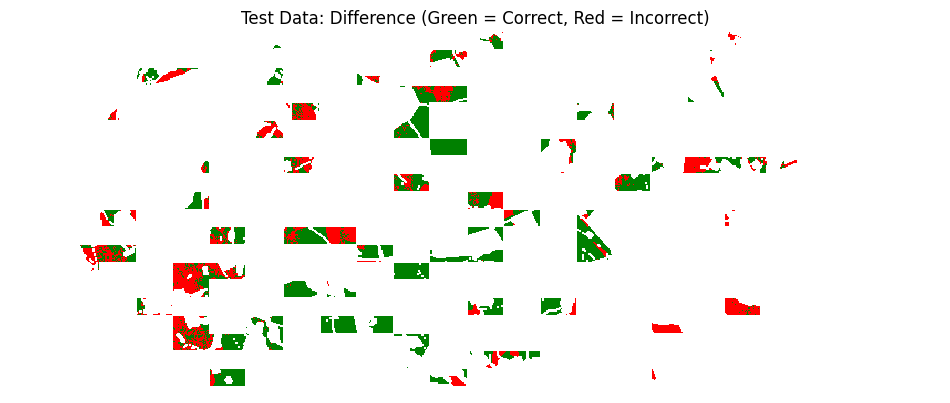

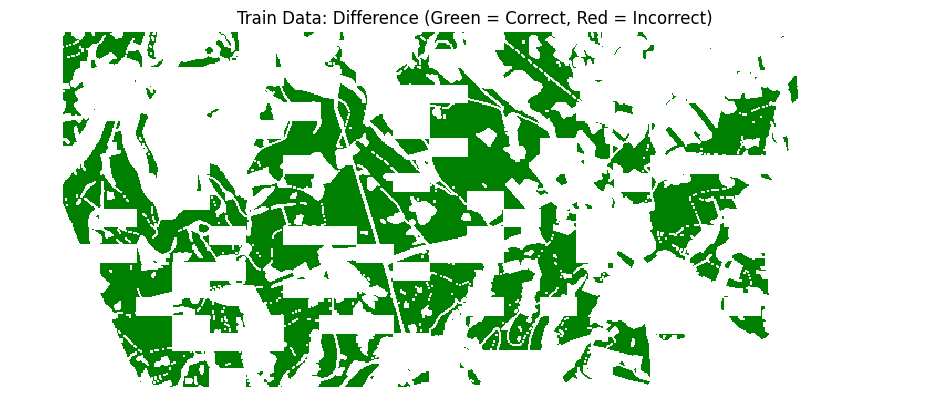

In [25]:
# Compute the difference arrays for test and train
difference_test_array = np.full_like(classification_tree_array, np.nan, dtype=np.float32)
for _, row in predictions_test_df.iterrows():
    x, y = int(row['original_x']), int(row['original_y'])
    if x < difference_test_array.shape[0] and y < difference_test_array.shape[1] and classification_tree_array[x, y] != 0:  # Ensure within bounds and not zero in classification
        difference_test_array[x, y] = classification_tree_array[x, y] - predicted_test_array[x, y]

difference_train_array = np.full_like(classification_tree_array, np.nan, dtype=np.float32)
for _, row in predictions_train_df.iterrows():
    x, y = int(row['original_x']), int(row['original_y'])
    if x < difference_train_array.shape[0] and y < difference_train_array.shape[1] and classification_tree_array[x, y] != 0:  # Ensure within bounds and not zero in classification
        difference_train_array[x, y] = classification_tree_array[x, y] - predicted_train_array[x, y]

# Create arrays for correct/incorrect predictions for test and train
correctness_test_array = np.where(np.isnan(difference_test_array), np.nan, np.where(difference_test_array == 0, 1, 0))
correctness_train_array = np.where(np.isnan(difference_train_array), np.nan, np.where(difference_train_array == 0, 1, 0))

# Plot Difference Data for Test
fig_diff_test, ax_diff_test = plt.subplots(figsize=(12, 8), dpi=100)
correctness_cmap = ListedColormap(['red', 'green'])
correctness_norm = BoundaryNorm([0, 0.5, 1], correctness_cmap.N)

im_correctness_test = ax_diff_test.imshow(correctness_test_array, cmap=correctness_cmap, norm=correctness_norm)
ax_diff_test.set_title('Test Data: Difference (Green = Correct, Red = Incorrect)')
ax_diff_test.axis('off')

# Plot Difference Data for Train
fig_diff_train, ax_diff_train = plt.subplots(figsize=(12, 8), dpi=100)

im_correctness_train = ax_diff_train.imshow(correctness_train_array, cmap=correctness_cmap, norm=correctness_norm)
ax_diff_train.set_title('Train Data: Difference (Green = Correct, Red = Incorrect)')
ax_diff_train.axis('off')

plt.show()